In [13]:
# ML model to predict if a received main is a spam or not
# Here in this code we implements a Naive Bayes classifier that uses Bayes Theorem to compute 
# the probability of a message being spam or ham based on word frequencies trains the model on 
# labeled data, evaluates its performance and predicts the class of new unseen messages.

In [14]:
# importing required libraries
import pandas as pd
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import CountVectorizer
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report
import seaborn as sns
import matplotlib.pyplot as plt

In [17]:
# Load and preprocess data

# Loading data using pandas
df = pd.read_csv('spam.csv', encoding='latin-1')[['v1', 'v2']]
backup_df = df.copy()
df.head(5)

,v1,v2
0,ham,"Go until jurong point, crazy.. Available only ..."
1,ham,Ok lar... Joking wif u oni...
2,spam,Free entry in 2 a wkly comp to win FA Cup fina...
3,ham,U dun say so early hor... U c already then say...
4,ham,"Nah I don't think he goes to usf, he lives aro..."


In [20]:
# changing column names and categorizing labels - ham = 0, spam = 1

df.columns = ['label', 'message']

df['label'] = df['label'].map({'ham' : 0, 'spam': 1})
df.head()

,label,message
0,0,"Go until jurong point, crazy.. Available only ..."
1,0,Ok lar... Joking wif u oni...
2,1,Free entry in 2 a wkly comp to win FA Cup fina...
3,0,U dun say so early hor... U c already then say...
4,0,"Nah I don't think he goes to usf, he lives aro..."


In [21]:
# Separating features and target variables

x = df['message']
y = df['label']

In [26]:
# splitting data into training and testing sets
#  split : 80% training and 20% testing

x_train, x_test, y_train, y_test = train_test_split(x, y, test_size=0.2, random_state=42)

In [33]:
# Convert Text Data into Numerical Form
# ML models cannot process raw text
# CountVectorizer converts text into word frequency vectors

vectorizer = CountVectorizer()
x_train_vec = vectorizer.fit_transform(x_train)
x_test_vec = vectorizer.transform(x_test)

In [34]:
# training a naive bayes model
# Multinomial naive bayes is well-suited for text classificaiton
# training the model using vecrorized training data

nb_model = MultinomialNB()
nb_model.fit(x_train_vec, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[3860., 597.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.14,-2.01]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 7735)","[[ 0., 0., 1.,..., 0., 9., 1.], [ 8.,23., 0.,..., 1., 0., 0.]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 7735)","[[-10.96,-10.96,-10.27,...,-10.96, -8.66,-10.27], [ -7.79, -6.81, -9.99,..., -9.29, -9.99, -9.99]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,7735


In [36]:
# making prediction on test data
y_pred = nb_model.predict(x_test_vec)


Accuracy: 98.39 %


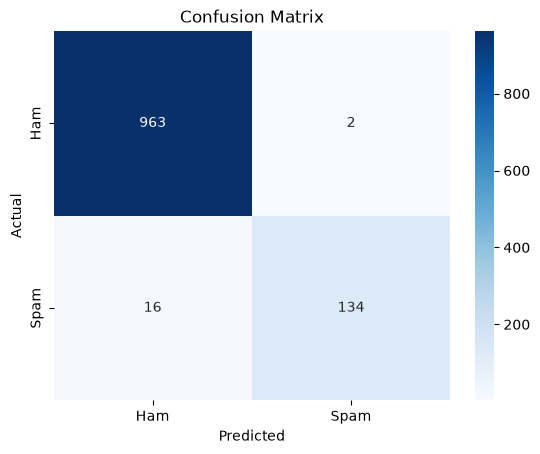

              precision    recall  f1-score   support

           0       0.98      1.00      0.99       965
           1       0.99      0.89      0.94       150

    accuracy                           0.98      1115
   macro avg       0.98      0.95      0.96      1115
weighted avg       0.98      0.98      0.98      1115



In [51]:
# Evaluating performance
# Accuracy, confusion matrix, precision, recall and F1 score

accuracy = accuracy_score(y_test, y_pred)
print(f'Accuracy: {accuracy*100:.2f} %')

# confusion matrix
cm = confusion_matrix(y_test, y_pred)
sns.heatmap(cm, annot = True, fmt= 'd', cmap='Blues',
            xticklabels=['Ham', 'Spam'],
            yticklabels=['Ham', 'Spam'])

plt.title('Confusion Matrix')
plt.xlabel('Predicted')
plt.ylabel('Actual')
plt.show()

print(classification_report(y_test, y_pred))

In [58]:
# testing model on new messages

new_msg = [
    'Congratulations! you received a deposit',
    'Hey, are we still dating?'
]

new_vec = vectorizer.transform(new_msg)
predections = nb_model.predict(new_vec)

for msg, pred in zip(new_msg, predections):
    label = 'Spam' if pred == 1 else 'Ham'
    print(f"message: '{msg}' => prediction: {label}")

message: 'Congratulations! you received a deposit' => prediction: Spam
message: 'Hey, are we still dating?' => prediction: Ham
